In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import zipfile, os, glob
from keras import optimizers
from PIL import Image
import numpy as np
from keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import image
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import Flatten
from keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
!wget -q https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip

with zipfile.ZipFile("cats_and_dogs_filtered.zip") as z:
    z.extractall()

base_dir  = "cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")              # train/cats & train/dogs
val_dir   = os.path.join(base_dir, "validation")         # validation/cats & validation/dogs

print("Eğitim klasörü:", train_dir)
print("Doğrulama klasörü:", val_dir)

Eğitim klasörü: cats_and_dogs_filtered/train
Doğrulama klasörü: cats_and_dogs_filtered/validation


In [ ]:
img_size = (160, 160)   # MobileNetV2 için uygun giriş boyutu
batch_sz = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=img_size, batch_size=batch_sz,
    shuffle=True, label_mode="binary")

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=img_size, batch_size=batch_sz,
    shuffle=False, label_mode="binary")

print("Sınıflar:", train_ds.class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Sınıflar: ['cats', 'dogs']


In [ ]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),  # yatay çevir
    layers.RandomRotation(0.1),        # ±10°
    layers.RandomZoom(0.1)             # %10 zoom
])

In [ ]:
clasifier = Sequential()
clasifier.add(Conv2D(32, (3, 3), input_shape = (600, 450, 3), activation = 'relu'))
clasifier.add(MaxPooling2D(pool_size = (2, 2)))
clasifier.add(Conv2D(64, (3, 3), activation = 'relu'))
clasifier.add(MaxPooling2D(pool_size = (2, 2)))
clasifier.add(Conv2D(128, (3, 3), activation = 'relu'))
clasifier.add(MaxPooling2D(pool_size = (2, 2)))
clasifier.add(Flatten())
clasifier.add(Dense(units = 128, activation = 'relu'))
clasifier.add(Dense(units = 1, activation = 'softmax'))
clasifier.compile(
    optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
test_datagen = ImageDataGenerator(rescale = 1./255)
training_set = train_datagen.flow_from_directory('/content/cats_and_dogs_filtered/train',
                                                 target_size = (600, 450),
                                                 batch_size = 32,
                                                 class_mode = 'categorical')
test_set = test_datagen.flow_from_directory('/content/cats_and_dogs_filtered/validation',
                                            target_size = (600, 450),
                                            batch_size = 32,
                                            class_mode = 'categorical')

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
# Initialising the CNN
classifier = Sequential()

# Step 1 - Convolution
classifier.add(Conv2D(32, (3, 3), input_shape=(600, 450, 3), activation='relu'))

# Step 2 - Pooling
classifier.add(MaxPooling2D(pool_size=(2, 2)))

# Adding a second convolutional layer
classifier.add(Conv2D(64, (3, 3), activation='relu'))
classifier.add(MaxPooling2D(pool_size=(2, 2)))

# Adding a third convolutional layer
classifier.add(Conv2D(128, (3, 3), activation='relu'))
classifier.add(MaxPooling2D(pool_size=(2, 2)))

# Step 4 - Flattening
classifier.add(Flatten())

# Step 5 - Full connection
classifier.add(Dense(units=128, activation='relu'))
classifier.add(Dense(units=4, activation='softmax'))

# Compiling the CNN
classifier.compile(
    optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
train_datagen = ImageDataGenerator(rescale=1./255,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

training_set = train_datagen.flow_from_directory('/content/cats_and_dogs_filtered/train',
                                                 target_size=(600, 450),
                                                 batch_size=32,
                                                 class_mode='categorical')

test_set = test_datagen.flow_from_directory('/content/cats_and_dogs_filtered/train',
                                            target_size=(600, 450),
                                            batch_size=32,
                                            class_mode='categorical')

history = classifier.fit_generator(training_set,
                                   steps_per_epoch=10000/32,
                                   epochs=50,
                                   validation_data=test_set,
                                   validation_steps=1000/32)

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

epochs = range(len(accuracy))

plt.figure()

plt.plot(epochs, accuracy, 'bo', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()

plt.show()


classifier.save('model_600_450_32_categorical.h5')

Found 2000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


AttributeError: 'Sequential' object has no attribute 'fit_generator'

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.4854 - loss: 35.5774 - val_accuracy: 0.4850 - val_loss: 0.7077
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5750 - loss: 0.6615 - val_accuracy: 0.5200 - val_loss: 0.7257
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6063 - loss: 0.6363 - val_accuracy: 0.5300 - val_loss: 0.7564
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6429 - loss: 0.6110 - val_accuracy: 0.5225 - val_loss: 0.7421
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6966 - loss: 0.5625 - val_accuracy: 0.4925 - val_loss: 0.8885
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6993 - loss: 0.5307 - val_accuracy: 0.5750 - val_loss: 0.9004
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7647 - loss: 0.4599 - val_accuracy: 0.5800 - val_loss: 0.9462
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7830 - loss: 0.4403 - val_accuracy: 0.5775 -

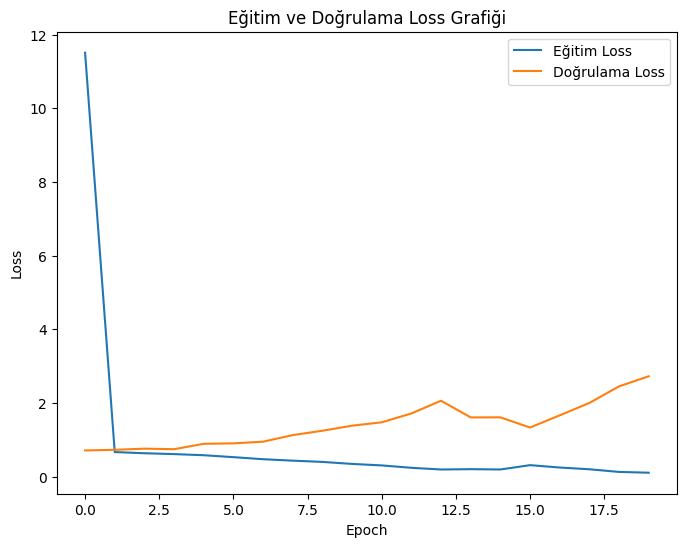

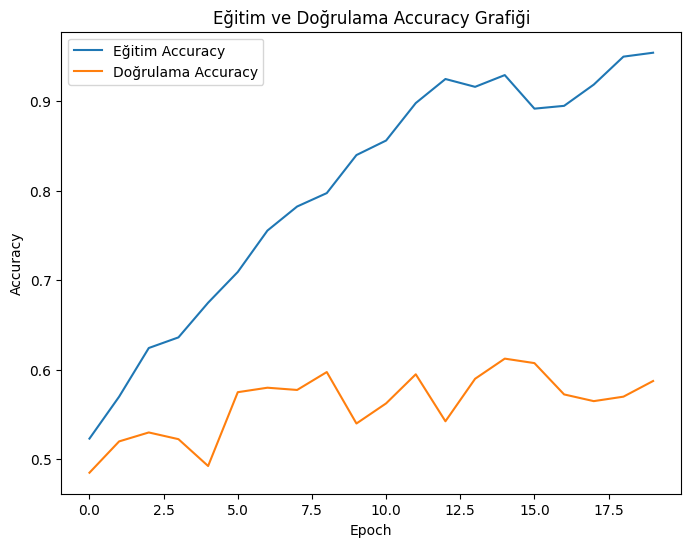

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Giriş boyutu
img_size = (128, 128)
batch_size = 32

# Dataset yükleme
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "cats_and_dogs_filtered/train",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "cats_and_dogs_filtered/train",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

# Performans iyileştirme için cache + prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# CNN Modeli
model = models.Sequential()

# 1. Convolution + Pooling
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)))
model.add(layers.MaxPooling2D((2, 2)))

# 2. Convolution + Pooling
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# 3. Convolution + Pooling
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Flatten
model.add(layers.Flatten())

# Fully Connected Layers
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(1, activation='sigmoid'))  # binary classification

# Derleyici
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Eğitim
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# Eğitim ve Doğrulama Loss Grafiği
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Eğitim Loss')
plt.plot(history.history['val_loss'], label='Doğrulama Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Eğitim ve Doğrulama Loss Grafiği')
plt.legend()
plt.show()

# Eğitim ve Doğrulama Accuracy Grafiği
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Eğitim Accuracy')
plt.plot(history.history['val_accuracy'], label='Doğrulama Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Eğitim ve Doğrulama Accuracy Grafiği')
plt.legend()
plt.show()

# Modeli Kaydetme
model.save('cats_vs_dogs_custom_cnn.h5')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
OLASILIK (1=dog): 0.2669573 → CAT


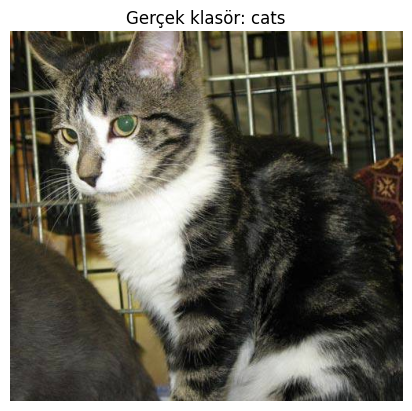

In [ ]:
import numpy as np, PIL.Image as Image, random, matplotlib.pyplot as plt
test_path = random.choice(list(glob.glob(os.path.join(val_dir, "*", "*.jpg"))))
plt.imshow(Image.open(test_path)); plt.axis('off'); plt.title("Gerçek klasör: " + os.path.basename(os.path.dirname(test_path)))
img = Image.open(test_path).resize(img_size)
arr = np.expand_dims(np.array(img) / 255.0, 0)
pred = model.predict(arr)[0][0]
print("OLASILIK (1=dog):", pred, "→", ("DOG" if pred > 0.5 else "CAT"))